# ECM cell cycle and death PySB model
Attempting to recereate Austin Oleskie's and Jérémie Mahrlens' model with minimal code

Running ODE and stochastic simulations from the same model file.

In [1]:
import os
import sys
sys.path.insert(0, "./cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../Data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

### Define time range for entire notebook

In [2]:
t = np.linspace(0, 5000, 50001)
# t = np.linspace(0, 10000, 100001)
# t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)


### Simulate ODE model from attempt at standardized model

In [3]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False).run(); #deterministic simulation

### Define observables to plot (will be reused)

In [4]:
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A

### Plot ODE simulation output of new model file

<Axes: xlabel='Time (h)', ylabel='Concentration'>

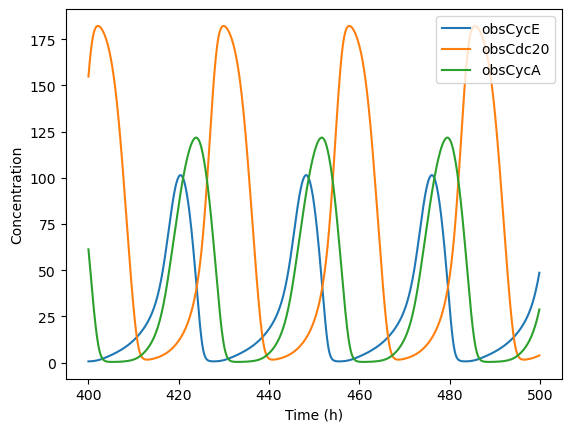

In [5]:

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(4000,5000), legend=True)


### Simulate model with stochastic simulator

In [6]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False);
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False, seed=33); 


<Axes: xlabel='Time (h)', ylabel='Concentration'>

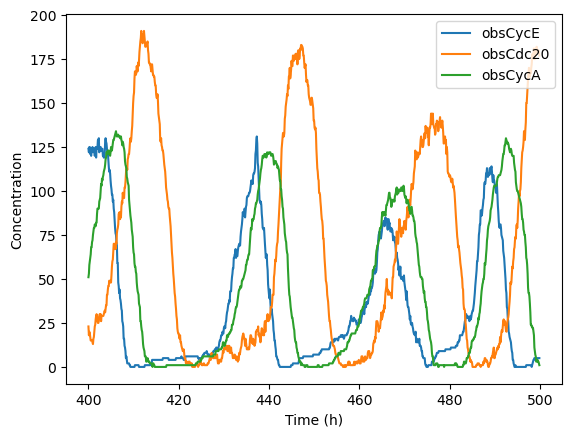

In [7]:
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(4000,5000), legend=True)

In [8]:
omega = 200
ecm_conditions = pd.read_csv('ECM_conditions.csv', index_col=[0])
ecm_conditions

,stiffness,drug,species,value
condition,,,,
stiff_DMSO,stiff,DMSO,AKT,1.0
stiff_DMSO,stiff,DMSO,ERK,1.0
stiff_DMSO,stiff,DMSO,FAK,1.0
int_DMSO,intermediate,DMSO,AKT,1.0
int_DMSO,intermediate,DMSO,ERK,1.0
int_DMSO,intermediate,DMSO,FAK,0.6
soft_DMSO,soft,DMSO,AKT,0.6
soft_DMSO,soft,DMSO,ERK,1.0
soft_DMSO,soft,DMSO,FAK,0.4


In [9]:
conditions = ecm_conditions.index.unique().tolist()
conditions


['stiff_DMSO', 'int_DMSO', 'soft_DMSO', 'stiff_erl', 'int_erl', 'soft_erl']

In [10]:
input_vals = pd.Series(ecm_conditions.loc['int_erl']['value'].to_list())
input_vals.index = ecm_conditions.loc['int_erl']['species'].to_list()
model.parameters['ERK'].value = input_vals['ERK']
model.parameters['FAK'].value = input_vals['FAK']
model.parameters['AKT'].value = input_vals['AKT']


<Axes: xlabel='Time (h)', ylabel='Concentration'>

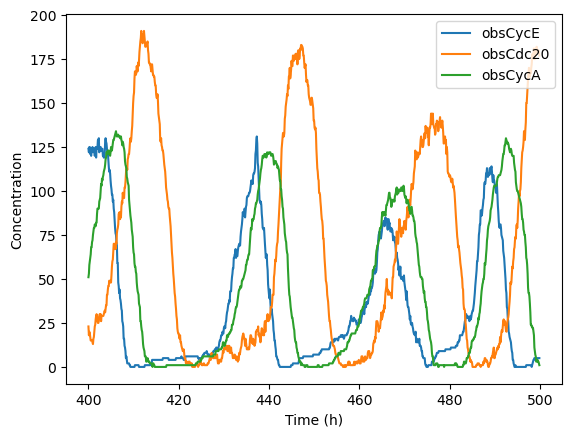

In [11]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False);
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False, seed=33); 
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(4000,5000), legend=True)

### ODE simulations

In [12]:
for condition in ecm_conditions.index.unique().tolist():
    input_vals = pd.Series(ecm_conditions.loc[condition]['value'].to_list())
    input_vals.index = ecm_conditions.loc[condition]['species'].to_list()
    model.parameters['ERK'].value = input_vals['ERK']
    model.parameters['FAK'].value = input_vals['FAK']
    model.parameters['AKT'].value = input_vals['AKT']

    print(f"Running ODE simulation for {condition}...")
   
    simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation
    yout = simres.observables;

    filename = Path(SAVE_DIR, f'ODE_sim_{condition}_param_orig.csv')
    if OVERWRITE or not os.path.exists(filename):
        print(f"Saving to {filename}...")
        np.savetxt(filename, yout, delimiter=',')
    else:
        print(f"File {filename} already exists. Skipping...")

Running ODE simulation for stiff_DMSO...
Saving to /Users/darren/ECM_mod_output/ODE_sim_stiff_DMSO_param_orig.csv...
Running ODE simulation for int_DMSO...
Saving to /Users/darren/ECM_mod_output/ODE_sim_int_DMSO_param_orig.csv...
Running ODE simulation for soft_DMSO...
Saving to /Users/darren/ECM_mod_output/ODE_sim_soft_DMSO_param_orig.csv...
Running ODE simulation for stiff_erl...
Saving to /Users/darren/ECM_mod_output/ODE_sim_stiff_erl_param_orig.csv...
Running ODE simulation for int_erl...
Saving to /Users/darren/ECM_mod_output/ODE_sim_int_erl_param_orig.csv...
Running ODE simulation for soft_erl...
Saving to /Users/darren/ECM_mod_output/ODE_sim_soft_erl_param_orig.csv...


### Stochastic simulations

In [13]:
for condition in ecm_conditions.index.unique().tolist():
    input_vals = pd.Series(ecm_conditions.loc[condition]['value'].to_list())
    input_vals.index = ecm_conditions.loc[condition]['species'].to_list()
    model.parameters['ERK'].value = input_vals['ERK']
    model.parameters['FAK'].value = input_vals['FAK']
    model.parameters['AKT'].value = input_vals['AKT']

    print(f"Running stochastic simulation for {condition}...")

    sim = BngSimulator(model, tspan=t, verbose=False); #stochastic simulator
    simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
    yout = simres.observables;

    filename = Path(SAVE_DIR, f'stoch_sim_{condition}_param_orig.csv')
    if OVERWRITE or not os.path.exists(filename):
        print(f"Saving to {filename}...")
        np.savetxt(filename, yout, delimiter=',')
    else:
        print(f"File {filename} already exists. Skipping...")

Running stochastic simulation for stiff_DMSO...
Saving to /Users/darren/ECM_mod_output/stoch_sim_stiff_DMSO_param_orig.csv...
Running stochastic simulation for int_DMSO...
Saving to /Users/darren/ECM_mod_output/stoch_sim_int_DMSO_param_orig.csv...
Running stochastic simulation for soft_DMSO...
Saving to /Users/darren/ECM_mod_output/stoch_sim_soft_DMSO_param_orig.csv...
Running stochastic simulation for stiff_erl...
Saving to /Users/darren/ECM_mod_output/stoch_sim_stiff_erl_param_orig.csv...
Running stochastic simulation for int_erl...
Saving to /Users/darren/ECM_mod_output/stoch_sim_int_erl_param_orig.csv...
Running stochastic simulation for soft_erl...
Saving to /Users/darren/ECM_mod_output/stoch_sim_soft_erl_param_orig.csv...
